# 🤖 PREP_02 — Analisis Sentimen IndoBERT (X2)
## Tesis: Prediksi Volatilitas Return Saham Energi LQ45 — Ilda Nurida (ITS)
**Mesin:** IndoBERT-base-p2 fine-tuned (3 kelas) · **Output:** `skor_sentimen_harian.csv` (X2)
> Jalankan di **Google Colab (GPU)**. Sel A–D siapkan data · Sel E–I fine-tune & skor · Sel J–N tabel/grafik/export Bab 4.

## ⚙️ SEL A — Setup & Konfigurasi

In [8]:
# ════ CELL A : SETUP (FIXED & CLEAN) ════

!pip install -q transformers torch scikit-learn sentencepiece

import warnings
warnings.filterwarnings('ignore')

import re
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path

# =========================
# ROOT PATH (PATH UTAMA THESIS)
# =========================
ROOT = Path(
    r"E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026"
)

# =========================
# FOLDER DATASET
# =========================
DIR_FINAL = ROOT / "03_dataset" / "final"
DIR_PROCESSED = ROOT / "03_dataset" / "processed"

# =========================
# OUTPUT (FOLDER YANG SUDAH ADA)
# =========================
DIR_OUT = ROOT / "02_preprocessing" / "sentimen_indobert" / "output_sentimen 1"

# supaya cell lain gak error
DIR_TABLE = DIR_OUT
DIR_IMG = DIR_OUT

# =========================
# EMITEN ORDER
# =========================
URUTAN_EMITEN = ['ADRO','ADMR','ITMG','PTBA','MEDC','AKRA','PGAS']

# =========================
# DEVICE
# =========================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("ROOT:", ROOT)
print("DIR_FINAL:", DIR_FINAL)
print("Output:", DIR_OUT)

Device: cpu
ROOT: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
DIR_FINAL: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final
Output: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1



[notice] A new release of pip available: 22.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 📂 SEL B — Load Berita

In [9]:
# ════ SEL B : LOAD BERITA ════
PATH_BERITA = DIR_FINAL / 'berita_gabungan_semua_sumber_FINAL.csv'
assert PATH_BERITA.exists(), f'File berita tidak ditemukan:\n{PATH_BERITA}'

df_berita = pd.read_csv(PATH_BERITA, encoding='utf-8-sig')
df_berita['Tanggal'] = pd.to_datetime(df_berita['Tanggal'], errors='coerce')
df_berita = df_berita.sort_values(['Kode_Emiten','Tanggal']).reset_index(drop=True)

def bersih_ringan(t):
    if not isinstance(t,str): return ''
    t = re.sub(r'http\S+|www\.\S+',' ',t)
    t = re.sub(r'\[Gambas.*?\]|Lihat juga Video.*',' ',t,flags=re.IGNORECASE)
    return re.sub(r'\s+',' ',t).strip()

df_berita['Teks'] = df_berita['Headline'].apply(bersih_ringan)
df_berita = df_berita[df_berita['Teks'].str.len()>0].reset_index(drop=True)
print(f'Total artikel: {len(df_berita):,} | {df_berita["Tanggal"].min().date()} -> {df_berita["Tanggal"].max().date()}')
print(df_berita['Kode_Emiten'].value_counts().to_string())

Total artikel: 4,150 | 2022-01-01 -> 2026-06-24
Kode_Emiten
PGAS    1082
PTBA     982
ADRO     892
MEDC     640
AKRA     217
ITMG     208
ADMR     129


## 🏷️ SEL C — Auto-label (untuk lembar anotasi)

In [10]:
# ════ SEL C : AUTO-LABEL (revisi) ════
KATA_POSITIF = {
 'naik','meningkat','tumbuh','menguat','melonjak','melesat','meroket','melejit',
 'terbang','rebound','rally','bullish','surplus','profit','keuntungan','rekor',
 'tertinggi','dividen','buyback','ekspansi','akuisisi','ipo','kontrak baru','optimis','pemulihan',
 'solid','cuan','top gainers','gainers','positif','cemerlang','sukses','raih',
 'menguntungkan','ekspor naik','produksi naik','harga batu bara naik','potensi cuan',
 # kata ambigu HARUS berupa frasa, bukan kata tunggal:
 'laba naik','laba melonjak','laba tumbuh','laba meningkat','laba melesat','catat laba',
 'untung besar','saham diborong','banyak dibeli','laba bersih naik','laba bersih tumbuh',
 'laba bersih melonjak','pendapatan naik','pendapatan tumbuh',
}

KATA_NEGATIF = {
 'turun','menurun','melemah','anjlok','ambles','jeblok','ambruk','terjun','jatuh',
 'merosot','terpangkas','rugi','kerugian','defisit','minus','bangkrut','pailit','default',
 'gagal bayar','delisting','koreksi','tertekan','bearish','rontok','negatif','buruk','tekanan',
 'sanksi','krisis','perlambatan','kontraksi','phk','pemangkasan','profit taking','outflow',
 'net sell','jual asing','tergerus','underperform','gugatan','denda','lesu','terpuruk',
 'oversupply','permintaan turun','ekspor turun','produksi turun','harga gas mahal',
 'harga batu bara turun','larangan ekspor','resesi','khawatir',
 # frasa baru supaya negatif lebih terdeteksi (ini yang tadinya "dimakan" oleh kata 'laba'):
 'laba turun','laba anjlok','laba merosot','laba tergerus','laba minus','laba menurun',
 'laba bersih turun','laba bersih anjlok','laba bersih merosot','rugi bersih',
 'pendapatan turun','pendapatan menurun','pendapatan anjlok',
 'kecelakaan','kebakaran','ledakan','mogok kerja','korupsi','skandal',
 'investor kabur','keluar bursa','penyelidikan','dugaan pelanggaran','izin dicabut',
 'downgrade','revisi turun','pangkas target harga','prospek suram','anjlok tajam',
 'turun tajam','saham nyungsep','nyungsep','tuntutan hukum','kredit macet',
}

def auto_label(teks):
    t = str(teks).lower()
    p = sum(1 for k in KATA_POSITIF if k in t)
    n = sum(1 for k in KATA_NEGATIF if k in t)
    return 'Positif' if p > n else 'Negatif' if n > p else 'Netral'

df_berita['Label_Auto'] = df_berita['Teks'].apply(auto_label)
print(df_berita['Label_Auto'].value_counts().to_string())

Label_Auto
Netral     2707
Positif    1054
Negatif     389


---
# 🔥 FASE 2 — FINE-TUNING (jalankan setelah 800 label dikoreksi)
---
## 🎯 SEL E — Load Label Terkoreksi & Split

In [11]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

PATH_LABELED = Path(
    r"E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen\anotasi_sentimen_VALID_gabungan.csv"
)

assert PATH_LABELED.exists(), f'File tidak ditemukan:\n{PATH_LABELED}'

# WAJIB load dulu
lab = pd.read_csv(PATH_LABELED, encoding='utf-8-sig')

print("Kolom dataset:")
print(lab.columns.tolist())
print("Shape:", lab.shape)

lab['Label_Manual'] = (
    lab['Label_Manual']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        'positif': 'Positif',
        'netral': 'Netral',
        'negatif': 'Negatif'
    })
)

lab = lab.dropna(subset=['Label_Manual']).reset_index(drop=True)

LABEL2ID = {
    'Negatif': 0,
    'Netral': 1,
    'Positif': 2
}

ID2LABEL = {v: k for k, v in LABEL2ID.items()}

lab['label_id'] = lab['Label_Manual'].map(LABEL2ID)

print("\nDistribusi label:")
print(lab['Label_Manual'].value_counts())

tr, va = train_test_split(
    lab,
    test_size=0.2,
    stratify=lab['label_id'],
    random_state=42
)

print(f"\nTrain: {len(tr)}")
print(f"Validasi: {len(va)}")

Kolom dataset:
['Kode_Emiten', 'Tanggal', 'Sumber', 'Headline', 'Teks', 'Label_Auto', 'Label_Manual']
Shape: (859, 7)

Distribusi label:
Label_Manual
Netral     565
Positif    243
Negatif     51
Name: count, dtype: int64

Train: 687
Validasi: 172


## 🔥 SEL F — Fine-tune IndoBERT-base-p2

In [12]:
# ════ SEL F : FINE-TUNE (DIPERBARUI — CLASS WEIGHTING) ════
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding
)
from datasets import Dataset
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score
import torch.nn as nn
import numpy as np

MODEL_BASE = 'indobenchmark/indobert-base-p2'
MAX_LEN = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_BASE)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_BASE, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID
).to(DEVICE)

# ── Dataset HuggingFace (menggantikan class DS lama) ──
train_ds = Dataset.from_pandas(
    tr[['Teks', 'label_id']].rename(columns={'Teks': 'text', 'label_id': 'label'}).reset_index(drop=True)
)
val_ds = Dataset.from_pandas(
    va[['Teks', 'label_id']].rename(columns={'Teks': 'text', 'label_id': 'label'}).reset_index(drop=True)
)

def tokenize_fn(batch):
    return tokenizer(batch['text'], truncation=True, max_length=MAX_LEN, padding=False)

train_tok = train_ds.map(tokenize_fn, batched=True).remove_columns(['text'])
val_tok = val_ds.map(tokenize_fn, batched=True).remove_columns(['text'])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# ── [KUNCI PERBAIKAN] Class Weighting — atasi imbalance kelas Negatif ──
class_weights_arr = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1, 2]),
    y=tr['label_id'].values
)
class_weights = torch.tensor(class_weights_arr, dtype=torch.float).to(DEVICE)

print('Class weights (Negatif, Netral, Positif):')
for i, w in enumerate(class_weights_arr):
    print(f'  {ID2LABEL[i]:8s} : {w:.4f}')

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.CrossEntropyLoss(weight=class_weights)
        loss = loss_fct(logits.view(-1, model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'accuracy': (preds == labels).mean(),
        'f1_macro': f1_score(labels, preds, average='macro'),
    }

args = TrainingArguments(
    output_dir=str(DIR_OUT / 'ckpt'),
    num_train_epochs=5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    warmup_ratio=0.1,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1_macro',   # bukan accuracy -> kelas Negatif tetap diperhatikan
    greater_is_better=True,
    logging_steps=20,
    save_total_limit=2,
    report_to='none',
    seed=42,
)

trainer = WeightedTrainer(
    model=model,
    args=args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()
print('✅ Fine-tuning selesai (dengan class weighting)')


You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p2
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/687 [00:00<?, ? examples/s]

Map:   0%|          | 0/172 [00:00<?, ? examples/s]

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


... (5 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

✅ Fine-tuning selesai (dengan class weighting)


In [13]:
print("Total dataset:", len(lab))
print("Train:", len(tr))
print("Validasi:", len(va))

Total dataset: 859
Train: 687
Validasi: 172


## 📊 SEL G — Evaluasi (Confusion Matrix + Akurasi) → Bab 4

AKURASI VALIDASI: 0.8779 (87.8%)

              precision    recall  f1-score   support

     Negatif       0.75      0.60      0.67        10
      Netral       0.93      0.88      0.90       113
     Positif       0.80      0.92      0.86        49

    accuracy                           0.88       172
   macro avg       0.83      0.80      0.81       172
weighted avg       0.88      0.88      0.88       172



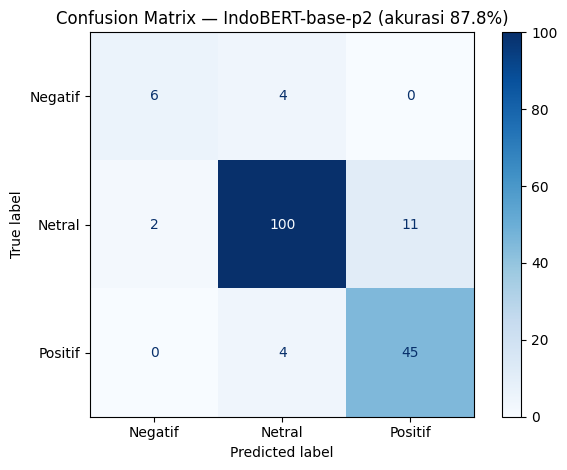

Saved: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1\gambar\confusion_matrix.png


In [14]:
# ════ SEL G : EVALUASI (FIX PATH) ════
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np
import torch

# =========================
# PATH OUTPUT
# =========================
DIR_OUT = Path(
    r"E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\sentimen_indobert\output_sentimen 1"
)

DIR_GAMBAR = DIR_OUT / "gambar"
DIR_GAMBAR.mkdir(parents=True, exist_ok=True)


def prediksi_proba(texts, batch=64):
    model.eval()
    out = []

    with torch.no_grad():
        for i in range(0, len(texts), batch):
            enc = tokenizer(
                list(texts[i:i+batch]),
                truncation=True,
                padding=True,
                max_length=MAX_LEN,
                return_tensors='pt'
            ).to(DEVICE)

            logits = model(**enc).logits
            probs = torch.softmax(logits, dim=1)
            out.append(probs.cpu().numpy())

    return np.vstack(out)


proba_va = prediksi_proba(va['Teks'].tolist())
pred_va = proba_va.argmax(axis=1)
y_true = va['label_id'].values

acc = accuracy_score(y_true, pred_va)

print(f'AKURASI VALIDASI: {acc:.4f} ({acc*100:.1f}%)\n')

print(
    classification_report(
        y_true,
        pred_va,
        target_names=['Negatif', 'Netral', 'Positif']
    )
)

cm = confusion_matrix(y_true, pred_va)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negatif', 'Netral', 'Positif']
).plot(cmap='Blues')

plt.title(
    f'Confusion Matrix — IndoBERT-base-p2 (akurasi {acc*100:.1f}%)'
)
plt.tight_layout()

PATH_CM = DIR_GAMBAR / 'confusion_matrix.png'
plt.savefig(PATH_CM, dpi=150, bbox_inches='tight')
plt.show()

print("Saved:", PATH_CM)

## 🎯 SEL H — Prediksi Skor Sentimen SEMUA Artikel (X2)

In [15]:
# ════ SEL H : PREDIKSI X2 SEMUA ARTIKEL ════
proba_all=prediksi_proba(df_berita['Teks'].tolist())
p_neg,p_net,p_pos=proba_all[:,0],proba_all[:,1],proba_all[:,2]
df_hasil=df_berita.copy()
df_hasil['P_Negatif']=p_neg.round(4); df_hasil['P_Netral']=p_net.round(4); df_hasil['P_Positif']=p_pos.round(4)
df_hasil['Skor_Sentimen']=(p_pos-p_neg).round(4)              # X2 kontinu [-1,1]
df_hasil['Confidence']=proba_all.max(1).round(4)
df_hasil['Label_Sentimen']=pd.Series(proba_all.argmax(1)).map(ID2LABEL).values
df_hasil['Sentimen_Diskrit']=df_hasil['Label_Sentimen'].map({'Positif':1,'Netral':0,'Negatif':-1})
df_hasil.to_csv(DIR_OUT/'skor_sentimen_per_artikel.csv',index=False,encoding='utf-8-sig')
print('💾 skor_sentimen_per_artikel.csv'); print(df_hasil['Label_Sentimen'].value_counts().to_string())
print(f'Skor: mean={df_hasil["Skor_Sentimen"].mean():+.3f} std={df_hasil["Skor_Sentimen"].std():.3f}')

💾 skor_sentimen_per_artikel.csv
Label_Sentimen
Netral     2573
Positif    1323
Negatif     254
Skor: mean=+0.259 std=0.527


## 📊 SEL J — Distribusi Sentimen per Emiten → Tabel 4.x

Label_Sentimen  Positif  Netral  Negatif  Total  % Positif  % Netral  % Negatif
Kode_Emiten                                                                    
ADRO                365     439       88    892       40.9      49.2        9.9
ADMR                 70      37       22    129       54.3      28.7       17.1
ITMG                114      71       23    208       54.8      34.1       11.1
PTBA                282     664       36    982       28.7      67.6        3.7
MEDC                174     425       41    640       27.2      66.4        6.4
AKRA                110      95       12    217       50.7      43.8        5.5
PGAS                208     842       32   1082       19.2      77.8        3.0


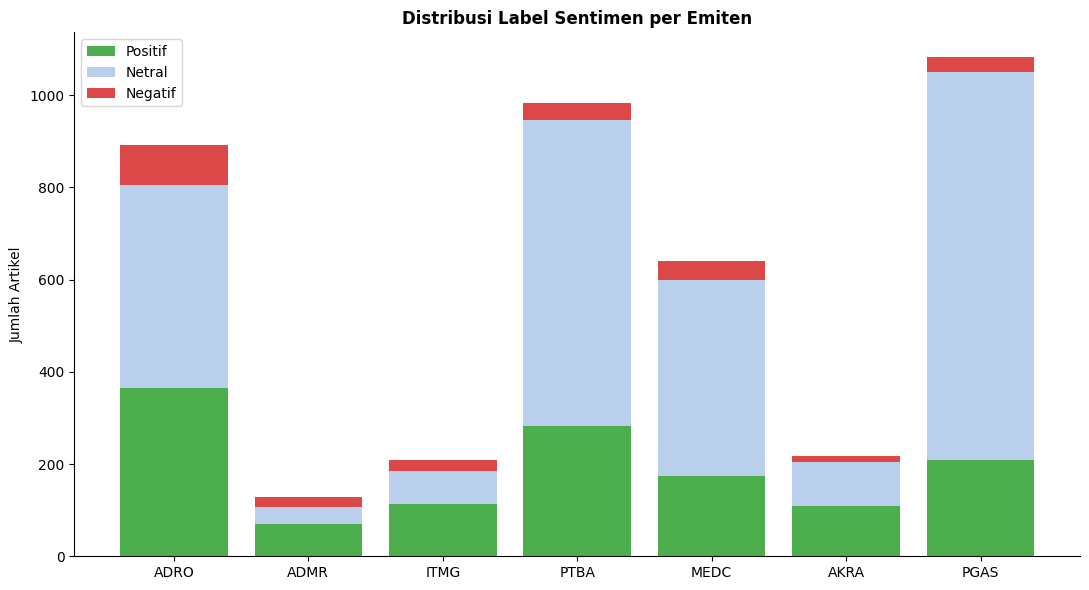

In [16]:
# ════ SEL J : DISTRIBUSI PER EMITEN ════

# cek kolom wajib
kolom_wajib = ['Kode_Emiten', 'Label_Sentimen', 'Headline']
missing = [c for c in kolom_wajib if c not in df_hasil.columns]
if missing:
    raise ValueError(f'Kolom tidak ditemukan: {missing}')

# pivot distribusi
pivot_dist = pd.pivot_table(
    df_hasil,
    index='Kode_Emiten',
    columns='Label_Sentimen',
    values='Headline',
    aggfunc='count',
    fill_value=0
).reindex(URUTAN_EMITEN, fill_value=0)

# pastikan semua label ada
for col in ['Positif', 'Netral', 'Negatif']:
    if col not in pivot_dist.columns:
        pivot_dist[col] = 0

pivot_dist = pivot_dist[['Positif', 'Netral', 'Negatif']]
pivot_dist['Total'] = pivot_dist.sum(axis=1)

# hindari division by zero
for c in ['Positif', 'Netral', 'Negatif']:
    pivot_dist[f'% {c}'] = np.where(
        pivot_dist['Total'] > 0,
        (pivot_dist[c] / pivot_dist['Total'] * 100).round(1),
        0
    )

print(pivot_dist.to_string())

# SAVE CSV
pivot_dist.to_csv(
    DIR_TABLE / 'tabel_distribusi_sentimen_per_emiten.csv',
    encoding='utf-8-sig'
)

# =========================
# PLOT
# =========================
fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(pivot_dist))

ax.bar(x, pivot_dist['Positif'],
       label='Positif', color='#2ca02c', alpha=0.85)

ax.bar(x, pivot_dist['Netral'],
       bottom=pivot_dist['Positif'],
       label='Netral', color='#aec7e8', alpha=0.85)

ax.bar(x, pivot_dist['Negatif'],
       bottom=pivot_dist['Positif'] + pivot_dist['Netral'],
       label='Negatif', color='#d62728', alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(pivot_dist.index)
ax.set_ylabel('Jumlah Artikel')
ax.set_title('Distribusi Label Sentimen per Emiten', fontweight='bold')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(
    DIR_IMG / 'distribusi_sentimen_per_emiten.png',
    dpi=150,
    bbox_inches='tight'
)
plt.show()

## 📅 SEL K — Agregasi Skor Sentimen Harian (+ forward-fill)

In [17]:
# ════ SEL K : AGREGASI HARIAN (REVISI AUDIT) ════
df_hasil['Tanggal']=pd.to_datetime(df_hasil['Tanggal'],errors='coerce')
df_agg=(df_hasil.groupby(['Kode_Emiten','Tanggal'])
    .agg(Skor_Sentimen=('Skor_Sentimen','mean'),
         Skor_Sentimen_Std=('Skor_Sentimen','std'),
         Confidence_Mean=('Confidence','mean'),
         Jumlah_Artikel=('Skor_Sentimen','count'),
         N_Positif=('Label_Sentimen',lambda x:(x=='Positif').sum()),
         N_Negatif=('Label_Sentimen',lambda x:(x=='Negatif').sum()),
         N_Netral =('Label_Sentimen',lambda x:(x=='Netral').sum()))
    .reset_index())
df_agg['Skor_Sentimen_Std']=df_agg['Skor_Sentimen_Std'].fillna(0)
df_agg['Skor_Sentimen']=df_agg['Skor_Sentimen'].round(4); df_agg['Ada_Berita']=1

# ── FIX AUDIT #1: pakai kalender hari bursa ASLI dari technical_features.csv
# (PREP_01) kalau tersedia — supaya tanggal 100% sinkron saat merge X1+X2.
# Fallback ke bdate_range generik kalau file belum ada (mis. urutan eksekusi
# PREP_02 sebelum PREP_01).
PATH_TEKNIKAL = DIR_PROCESSED / 'technical_features.csv'
if PATH_TEKNIKAL.exists():
    _tgl_teknikal = pd.read_csv(PATH_TEKNIKAL, usecols=['Date'])['Date']
    hari = pd.to_datetime(sorted(_tgl_teknikal.unique()))
    print(f'  ℹ️  Kalender hari bursa dipakai dari technical_features.csv '
          f'({len(hari)} hari, {hari.min().date()} → {hari.max().date()})')
else:
    hari = pd.bdate_range(df_agg['Tanggal'].min(), df_agg['Tanggal'].max())
    print(f'  ⚠️  technical_features.csv belum ada — fallback ke bdate_range '
          f'generik ({len(hari)} hari). Jalankan ulang SEL K setelah PREP_01 '
          f'selesai supaya kalender 100% sinkron.')

idx=pd.MultiIndex.from_product([URUTAN_EMITEN,hari],names=['Kode_Emiten','Tanggal'])
df_full=pd.DataFrame(index=idx).reset_index().merge(df_agg,on=['Kode_Emiten','Tanggal'],how='left')
df_full['Ada_Berita']=df_full['Ada_Berita'].fillna(0).astype(int)
df_full=df_full.sort_values(['Kode_Emiten','Tanggal'])
df_full['Skor_Sentimen']=df_full.groupby('Kode_Emiten')['Skor_Sentimen'].ffill().fillna(0.0)

# ── FIX AUDIT #2: Skor_Sentimen_Std (dispersi/ketidaksepakatan opini pasar)
# TETAP dipertahankan — forward-fill sejalan dengan Skor_Sentimen, bukan
# dibuang sebelum export seperti versi sebelumnya.
df_full['Skor_Sentimen_Std']=df_full.groupby('Kode_Emiten')['Skor_Sentimen_Std'].ffill().fillna(0.0)

for c in ['Jumlah_Artikel','N_Positif','N_Negatif','N_Netral']:
    df_full[c]=df_full[c].fillna(0).astype(int)
df_full['Skor_Sentimen_Mean']=df_full['Skor_Sentimen']
print('Total hari-emiten:',len(df_full)); print(df_full.head(8).to_string(index=False))

  ℹ️  Kalender hari bursa dipakai dari technical_features.csv (746 hari, 2023-04-03 → 2026-05-29)
Total hari-emiten: 5222
Kode_Emiten    Tanggal  Skor_Sentimen  Skor_Sentimen_Std  Confidence_Mean  Jumlah_Artikel  N_Positif  N_Negatif  N_Netral  Ada_Berita  Skor_Sentimen_Mean
       ADMR 2023-04-03            0.0                0.0              NaN               0          0          0         0           0                 0.0
       ADMR 2023-04-04            0.0                0.0              NaN               0          0          0         0           0                 0.0
       ADMR 2023-04-05            0.0                0.0              NaN               0          0          0         0           0                 0.0
       ADMR 2023-04-06            0.0                0.0              NaN               0          0          0         0           0                 0.0
       ADMR 2023-04-10            0.0                0.0              NaN               0          0        

## 📈 SEL L — Visualisasi Tren Sentimen Harian → Gambar 4.x

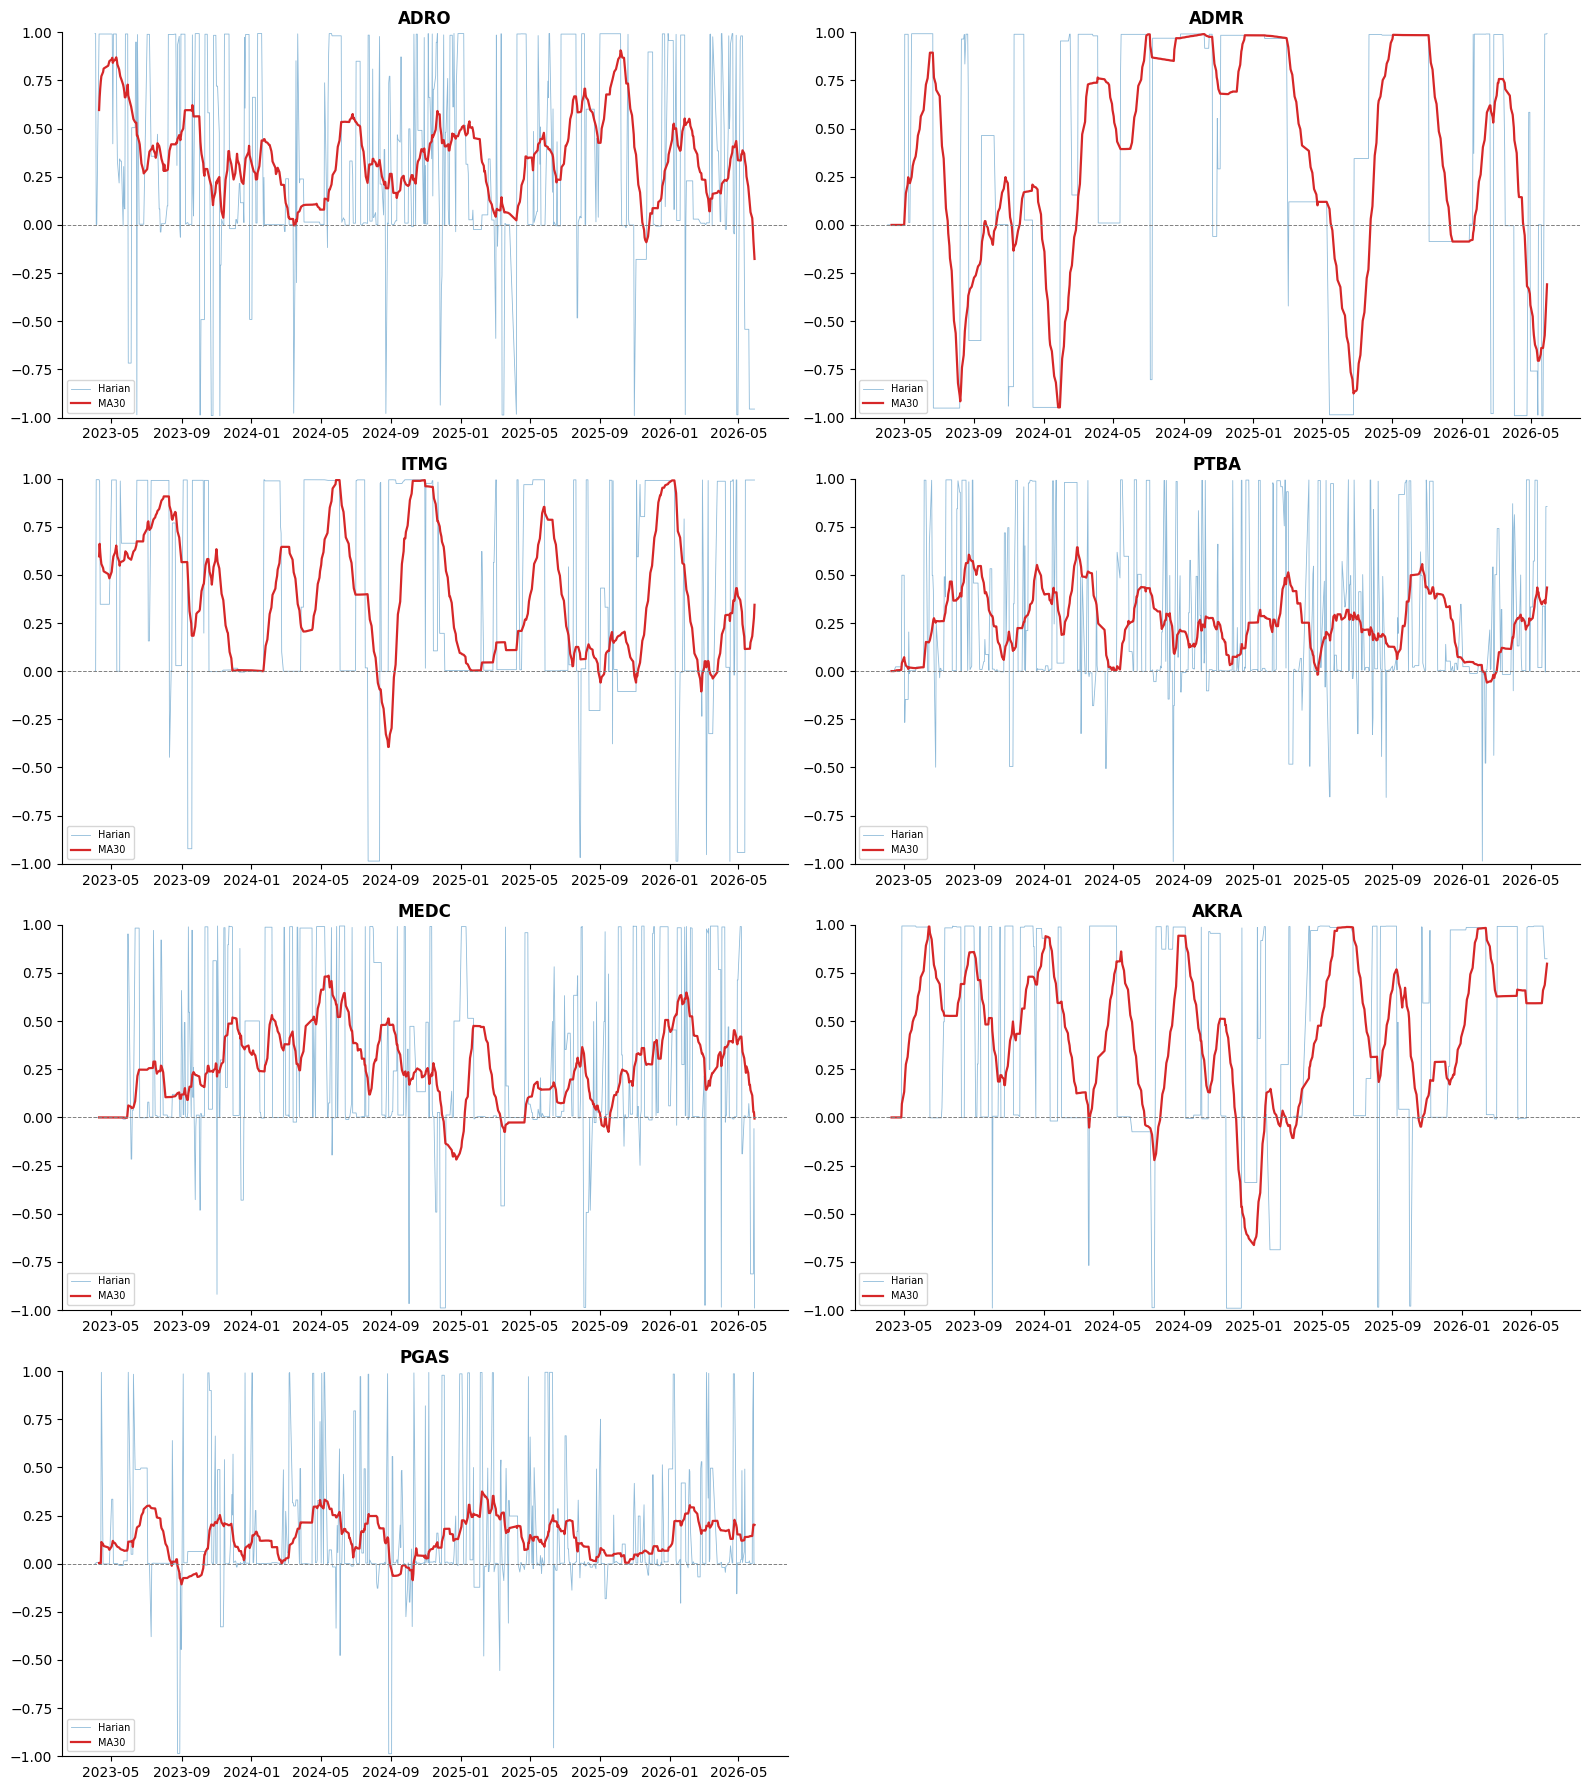

In [18]:
# ════ SEL L : TREN HARIAN ════
fig,axes=plt.subplots(4,2,figsize=(16,18)); axes=axes.flatten()
for i,em in enumerate(URUTAN_EMITEN):
    g=df_full[df_full['Kode_Emiten']==em].set_index('Tanggal')
    ax=axes[i]
    ax.plot(g.index,g['Skor_Sentimen'],lw=.6,color='#1f77b4',alpha=.5,label='Harian')
    ax.plot(g.index,g['Skor_Sentimen'].rolling(30,min_periods=5).mean(),lw=1.6,color='#d62728',label='MA30')
    ax.axhline(0,color='gray',ls='--',lw=.7); ax.set_title(em,fontweight='bold')
    ax.set_ylim(-1,1); ax.legend(fontsize=7); ax.spines[['top','right']].set_visible(False)
for j in range(len(URUTAN_EMITEN),len(axes)): axes[j].axis('off')
plt.tight_layout(); plt.savefig(DIR_GAMBAR/'tren_sentimen_harian.png',dpi=150,bbox_inches='tight'); plt.show()

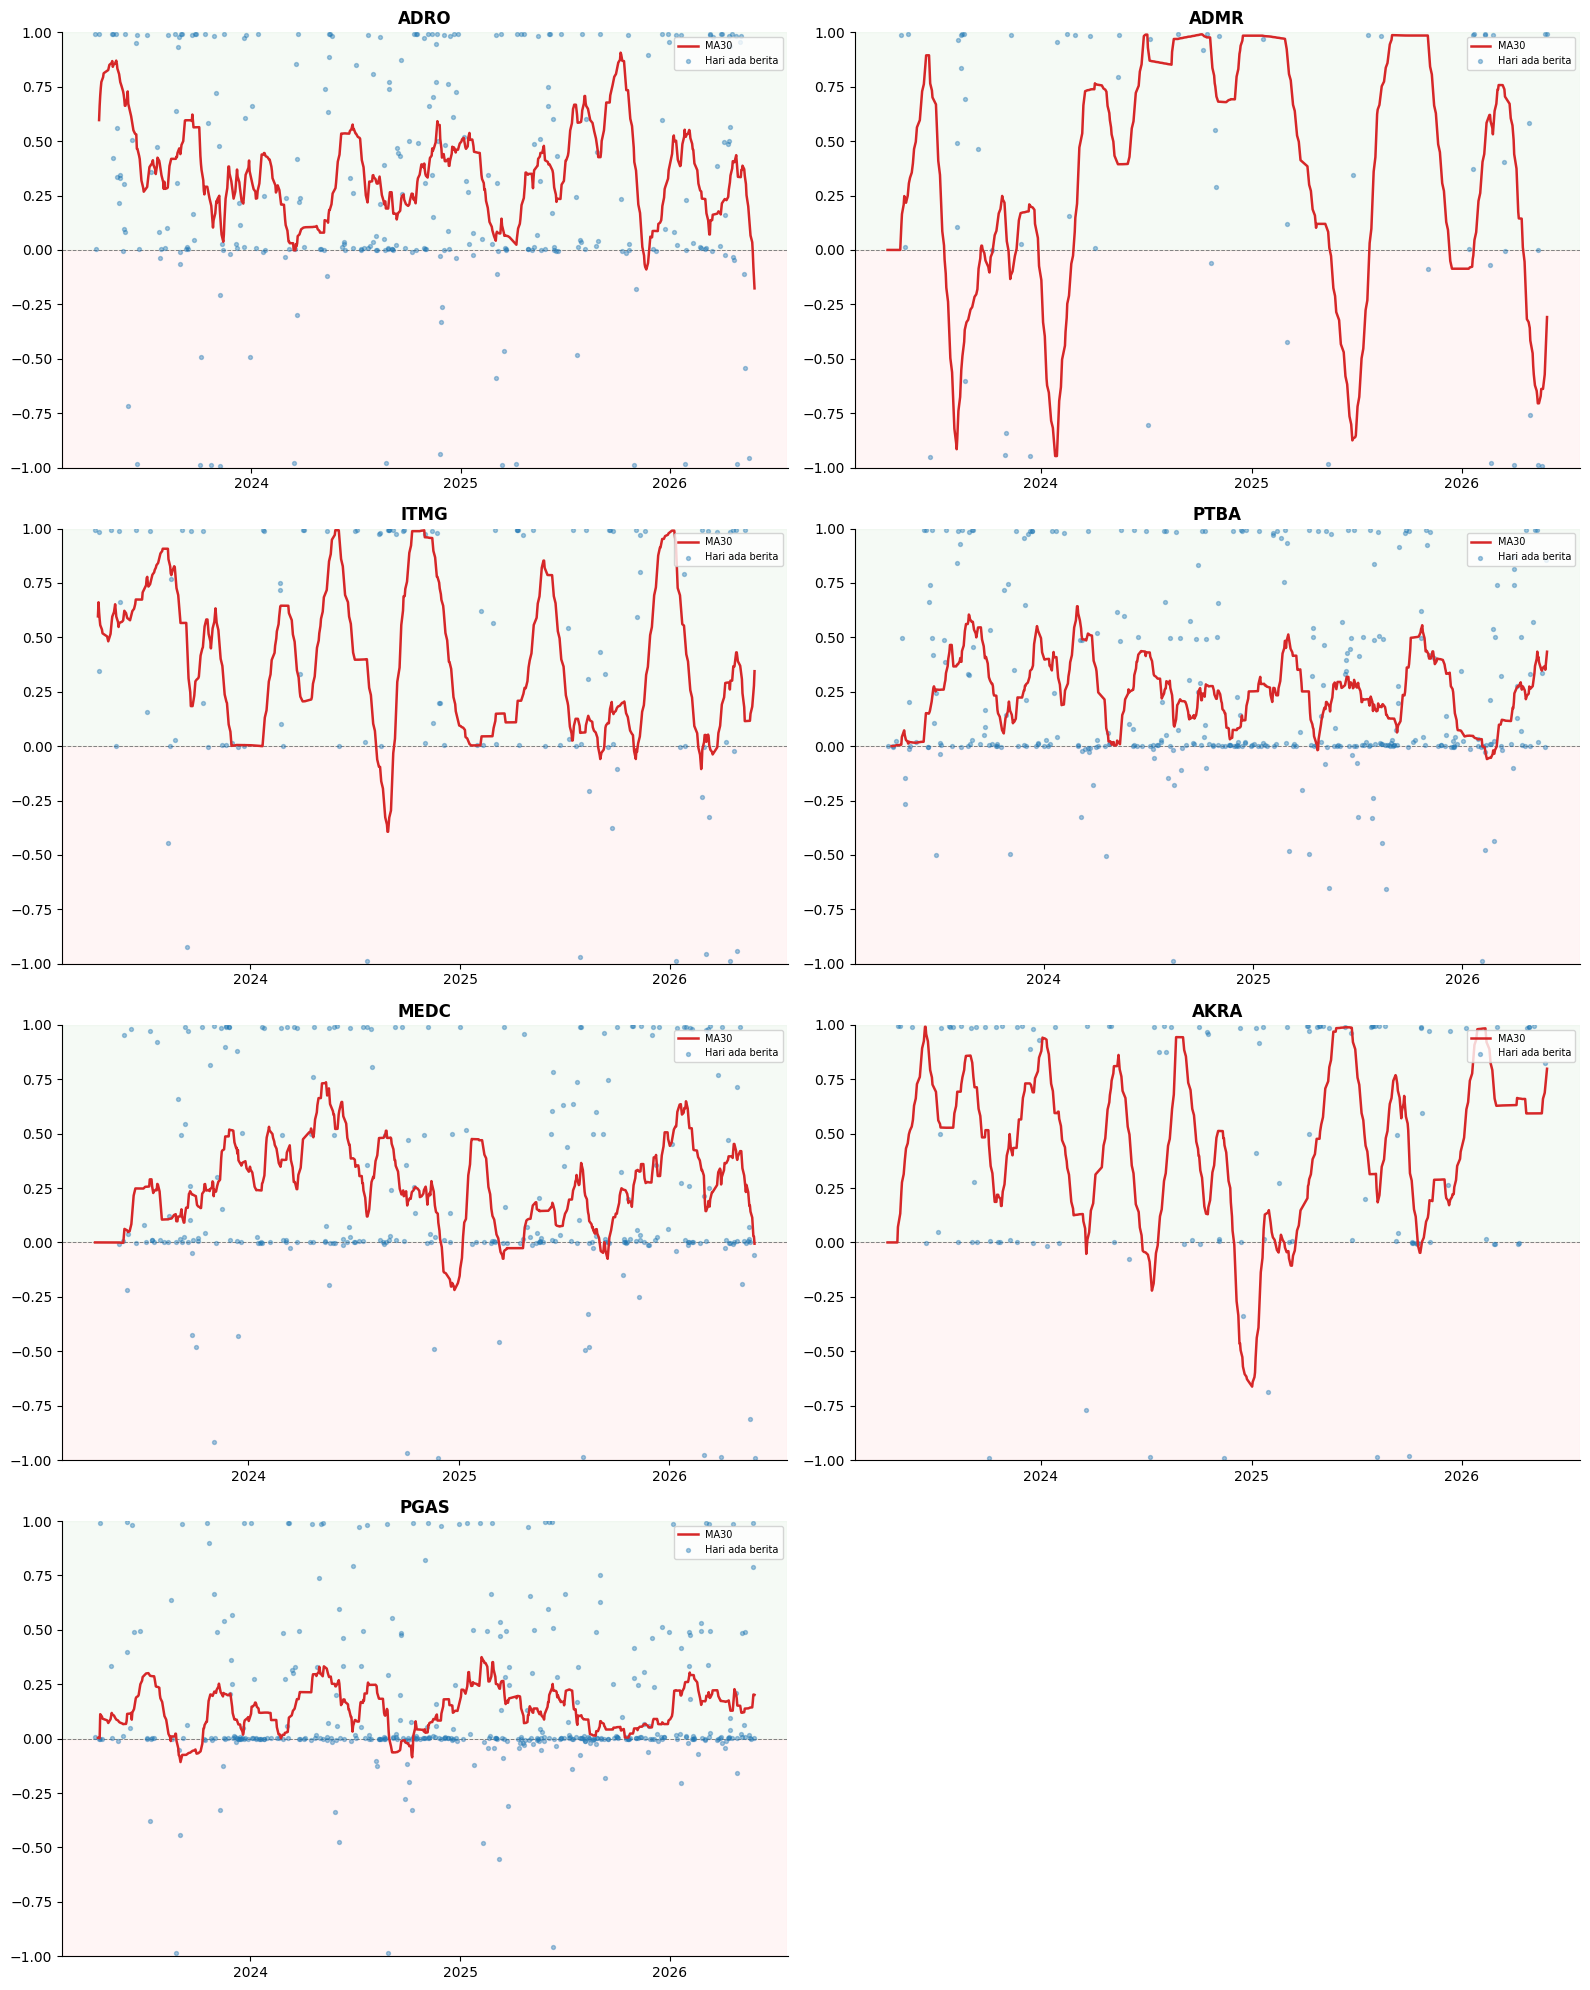

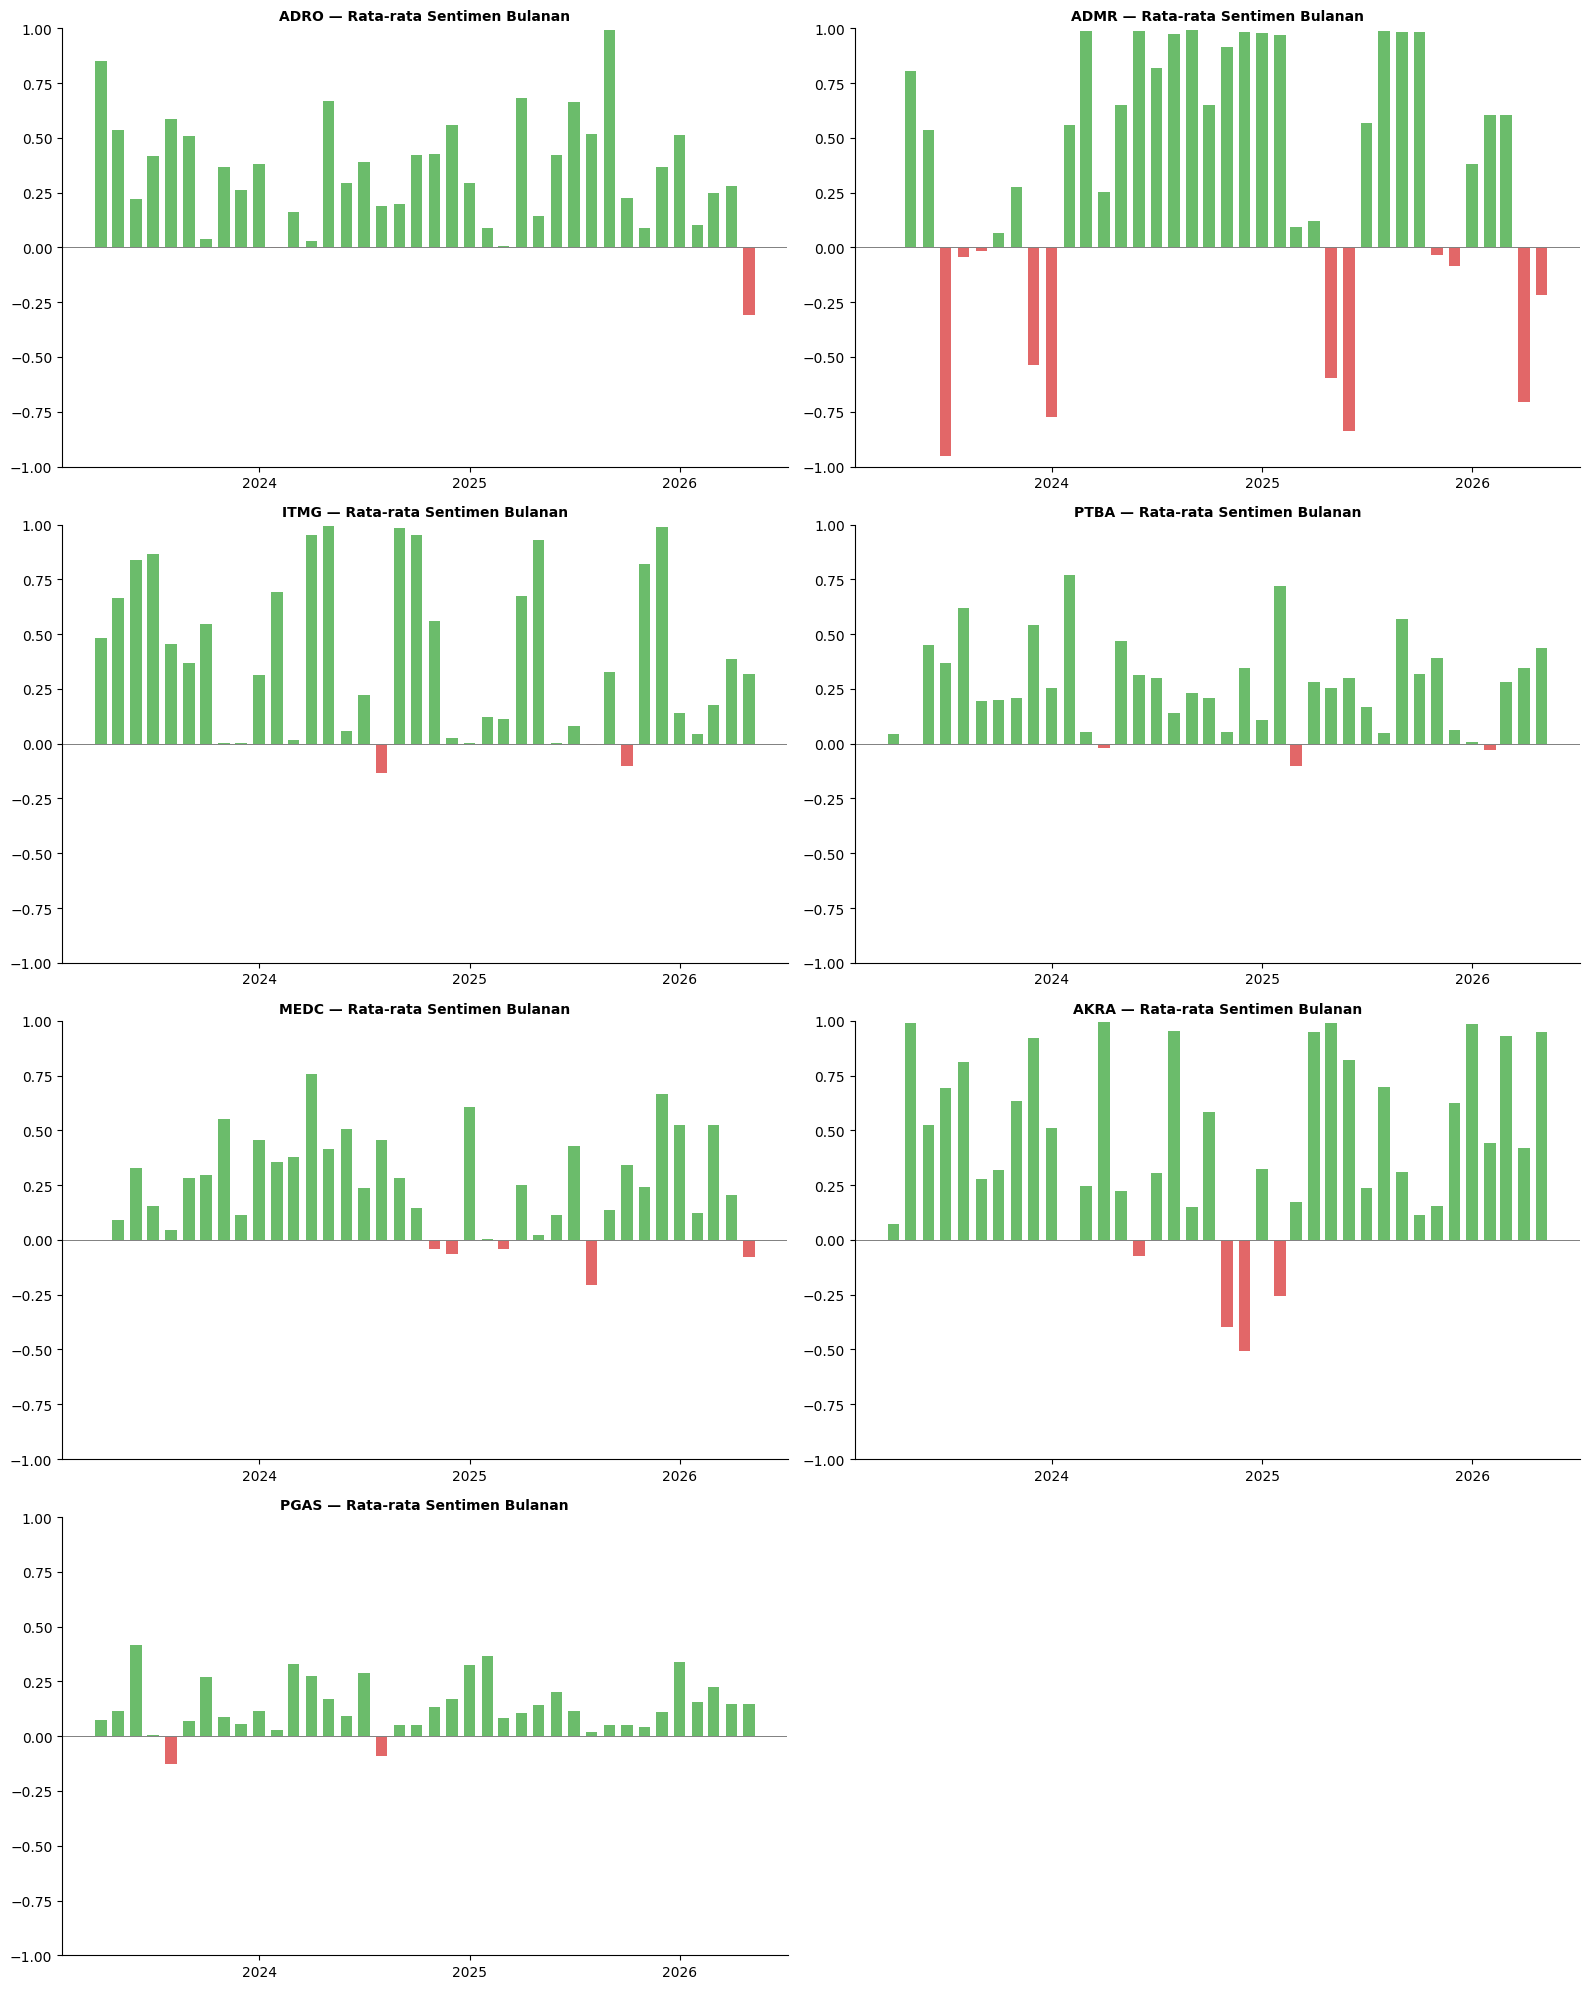

✅ Disimpan: tren_sentimen_harian_v2.png & tren_sentimen_bulanan.png


In [19]:
# ════ SEL L (VERSI DIPERBAIKI) — TREN SENTIMEN + VOLUME BERITA ════
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, axes = plt.subplots(4, 2, figsize=(16, 20),
                          gridspec_kw={'height_ratios': [1]*4})
axes = axes.flatten()

for i, em in enumerate(URUTAN_EMITEN):
    g = df_full[df_full['Kode_Emiten'] == em].set_index('Tanggal')
    ax = axes[i]

    # ── Panel utama: MA30 + scatter hari yang benar-benar ada berita ──
    ax.plot(g.index, g['Skor_Sentimen'].rolling(30, min_periods=5).mean(),
            lw=1.8, color='#d62728', label='MA30', zorder=3)

    # Hanya scatter di hari yang benar-benar ada berita (bukan forward-fill)
    if 'Ada_Berita' in g.columns:
        hari_berita = g[g['Ada_Berita'] == 1]
    else:
        hari_berita = g  # fallback kalau kolom tidak tersedia

    ax.scatter(hari_berita.index, hari_berita['Skor_Sentimen'],
               s=8, color='#1f77b4', alpha=0.4, label='Hari ada berita', zorder=2)

    # Shading area positif/negatif
    ax.axhspan(0, 1, color='green', alpha=0.04)
    ax.axhspan(-1, 0, color='red', alpha=0.04)
    ax.axhline(0, color='gray', ls='--', lw=0.7, zorder=1)

    ax.set_title(em, fontweight='bold')
    ax.set_ylim(-1, 1)
    ax.legend(fontsize=7, loc='upper right')
    ax.spines[['top', 'right']].set_visible(False)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

for j in range(len(URUTAN_EMITEN), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'tren_sentimen_harian_v2.png', dpi=150, bbox_inches='tight')
plt.show()


# ════ TAMBAHAN: PANEL VOLUME BERITA PER BULAN (opsional, per emiten) ════
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for i, em in enumerate(URUTAN_EMITEN):
    g = df_full[df_full['Kode_Emiten'] == em].copy()
    g['Bulan'] = pd.to_datetime(g['Tanggal']).dt.to_period('M')

    # Agregasi bulanan: rata-rata sentimen & jumlah artikel
    agg = g.groupby('Bulan').agg(
        Sentimen=('Skor_Sentimen', 'mean'),
        Jumlah_Artikel=('Jumlah_Artikel', 'sum') if 'Jumlah_Artikel' in g.columns else ('Skor_Sentimen', 'count')
    ).reset_index()
    agg['Bulan'] = agg['Bulan'].dt.to_timestamp()

    ax = axes[i]
    colors = ['#2ca02c' if v >= 0 else '#d62728' for v in agg['Sentimen']]
    ax.bar(agg['Bulan'], agg['Sentimen'], width=20, color=colors, alpha=0.7)
    ax.axhline(0, color='gray', lw=0.7)
    ax.set_title(f'{em} — Rata-rata Sentimen Bulanan', fontweight='bold', fontsize=10)
    ax.set_ylim(-1, 1)
    ax.spines[['top', 'right']].set_visible(False)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

for j in range(len(URUTAN_EMITEN), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'tren_sentimen_bulanan.png', dpi=150, bbox_inches='tight')
plt.show()

print('✅ Disimpan: tren_sentimen_harian_v2.png & tren_sentimen_bulanan.png')

In [20]:
# ════ FUNGSI TAMBAHAN — ZOOM TREN HARIAN KE 1 BULAN TERTENTU ════
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

def plot_tren_bulanan(emiten, tahun, bulan, simpan=True):
    """
    Menampilkan tren sentimen harian untuk 1 emiten pada 1 bulan tertentu.

    Parameter:
        emiten : str  -> contoh 'ADRO'
        tahun  : int  -> contoh 2024
        bulan  : int  -> 1-12
        simpan : bool -> simpan gambar ke DIR_GAMBAR jika True
    """
    g = df_full[df_full['Kode_Emiten'] == emiten].copy()
    g['Tanggal'] = pd.to_datetime(g['Tanggal'])
    mask = (g['Tanggal'].dt.year == tahun) & (g['Tanggal'].dt.month == bulan)
    g_bulan = g[mask].sort_values('Tanggal')

    if g_bulan.empty:
        print(f'Tidak ada data untuk {emiten} pada {bulan}/{tahun}')
        return

    fig, ax = plt.subplots(figsize=(10, 4))

    # Garis forward-fill (abu-abu tipis)
    ax.plot(g_bulan['Tanggal'], g_bulan['Skor_Sentimen'],
            lw=1.2, color='#898781', alpha=0.6, zorder=1)

    # Titik hanya di hari yang benar-benar ada berita
    if 'Ada_Berita' in g_bulan.columns:
        hari_berita = g_bulan[g_bulan['Ada_Berita'] == 1]
    else:
        hari_berita = g_bulan

    ax.scatter(hari_berita['Tanggal'], hari_berita['Skor_Sentimen'],
               s=40, color='#2a78d6', zorder=2, label='Hari ada berita')

    ax.axhspan(0, 1, color='green', alpha=0.04)
    ax.axhspan(-1, 0, color='red', alpha=0.04)
    ax.axhline(0, color='gray', ls='--', lw=0.7)

    nama_bulan = ['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des']
    ax.set_title(f'{emiten} — Tren Sentimen Harian, {nama_bulan[bulan-1]} {tahun}',
                 fontweight='bold')
    ax.set_ylim(-1, 1)
    ax.set_ylabel('Skor Sentimen')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d'))
    ax.set_xlabel('Tanggal')
    ax.legend(fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    if simpan:
        fname = f'tren_{emiten}_{tahun}_{bulan:02d}.png'
        plt.savefig(DIR_GAMBAR / fname, dpi=150, bbox_inches='tight')
        print(f'✅ Disimpan: {fname}')
    plt.show()


# ── Contoh pemakaian ──
# plot_tren_bulanan('ADRO', 2025, 7)   # tren ADRO bulan Juli 2025
# plot_tren_bulanan('ITMG', 2024, 6)   # tren ITMG bulan Juni 2024

## 💾 SEL M — Simpan X2 Harian + Quality Check

In [21]:
# ════ SEL M : SIMPAN + QC (REVISI AUDIT) ════
# FIX AUDIT #1: kolom kunci di-rename ke 'Emiten'/'Date' supaya PERSIS SAMA
# dengan technical_features.csv (PREP_01) — merge X1+X2 tidak akan gagal
# diam-diam gara-gara nama kolom beda ('Kode_Emiten'/'Tanggal' vs 'Emiten'/'Date').
# FIX AUDIT #2: Sentiment_Dispersion (std sentimen antar berita per hari)
# ikut disimpan — sebelumnya dihitung di SEL K tapi dibuang di sini.
df_final = df_full[[
    'Kode_Emiten', 'Tanggal', 'Skor_Sentimen', 'Skor_Sentimen_Std',
    'Jumlah_Artikel', 'Ada_Berita'
]].copy()

df_final = df_final.rename(columns={
    'Kode_Emiten': 'Emiten',
    'Tanggal': 'Date',
    'Skor_Sentimen': 'Sentiment_Mean',
    'Skor_Sentimen_Std': 'Sentiment_Dispersion',
    'Jumlah_Artikel': 'News_Count',
})

df_final['Date'] = pd.to_datetime(df_final['Date'])
df_final = df_final.sort_values(['Emiten', 'Date']).reset_index(drop=True)

path_final = DIR_PROCESSED / 'skor_sentimen_harian.csv'
df_final.to_csv(path_final, index=False, encoding='utf-8-sig')
print(f'✅ {path_final}  ({len(df_final):,} baris)')
print(f'   Kolom: {df_final.columns.tolist()}')

print('\nStatistik per emiten:')
print(df_final.groupby('Emiten')[['Sentiment_Mean','Sentiment_Dispersion']]
      .agg(['mean','std','min','max']).round(4).reindex(URUTAN_EMITEN).to_string())
print('\nMissing:', df_final.isnull().sum().sum(), '| Duplikat:', df_final.duplicated().sum())
print('Range tgl:', df_final['Date'].min().date(), '->', df_final['Date'].max().date())

✅ E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\skor_sentimen_harian.csv  (5,222 baris)
   Kolom: ['Emiten', 'Date', 'Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita']

Statistik per emiten:
       Sentiment_Mean                         Sentiment_Dispersion                     
                 mean     std     min     max                 mean     std  min     max
Emiten                                                                                 
ADRO           0.3385  0.5185 -0.9911  0.9943               0.1231  0.2524  0.0  1.3885
ADMR           0.3474  0.7350 -0.9914  0.9942               0.0582  0.2137  0.0  0.9757
ITMG           0.3830  0.5668 -0.9873  0.9943               0.0732  0.2567  0.0  1.4003
PTBA           0.2627  0.4243 -0.9887  0.9940               0.1464  0.2802  0.0  1.3616
MEDC           0.2529  0.4631 -0.9894  0.9940               0.0986  0.2382 

## 📦 SEL N — Export Final (siap merge dengan Y & X1)

In [22]:
# ════ SEL N : EXPORT READY FOR MERGE (REVISI AUDIT) ════
df_final.to_csv(DIR_PROCESSED/'sentiment_ready_for_merge.csv',index=False,encoding='utf-8-sig')
print('✅ sentiment_ready_for_merge.csv')
print(f'   Kolom kunci merge: Emiten, Date  (SAMA PERSIS dengan technical_features.csv)')
print(f'   Kolom fitur X2   : Sentiment_Mean, Sentiment_Dispersion, News_Count, Ada_Berita')
print()
print('📌 Contoh merge di notebook integrasi (05_integrasi_dataset.ipynb):')
print('   df_master = df_x1.merge(df_x2, on=[\'Date\', \'Emiten\'], how=\'inner\')')

✅ sentiment_ready_for_merge.csv
   Kolom kunci merge: Emiten, Date  (SAMA PERSIS dengan technical_features.csv)
   Kolom fitur X2   : Sentiment_Mean, Sentiment_Dispersion, News_Count, Ada_Berita

📌 Contoh merge di notebook integrasi (05_integrasi_dataset.ipynb):
   df_master = df_x1.merge(df_x2, on=['Date', 'Emiten'], how='inner')
